# Week 3: Gradient Boosting Model and Validation Framework

## 1. Project Introduction

In this phase of the project, we develop a machine learning-based demand forecasting model using the LightGBM (Light Gradient Boosting Machine) algorithm.

The main objective is to predict the daily sales demand of different products across multiple supermarket stores for October 2025.

We use historical sales information and engineered features to train the model, identify sales patterns and generate future demand predictions.

## 2. Dataset Description

The project uses historical supermarket sales data along with a prepared feature dataset.

The dataset contains approximately 502,000 training records and 23 columns.

The data includes information such as:

- Date: The date of the sales transaction.
- Store ID: Unique identification of each supermarket.
- SKU ID: Unique identification of each product.
- Units Sold: Actual quantity of products sold.
- Lag Features: Previous sales information.
- Rolling Mean Features: Average sales over previous time periods.
- Calendar Features: Year, month, day and week information.
- Other Business Features: Product, store and demand-related information.

## 3. Objective

The main objectives of this phase are:

1. Prepare historical data for machine learning.
2. Perform feature engineering to create meaningful prediction variables.
3. Train a LightGBM regression model.
4. Validate the model using time-based splitting.
5. Implement rolling-origin cross-validation.
6. Evaluate forecasting performance using WAPE, MAE and Forecast Bias.
7. Compare LightGBM performance with baseline forecasting models.
8. Analyze feature importance.
9. Generate daily sales forecasts for October 2025.
10. Save the trained model and forecasting results.

## 4. Algorithm Used: LightGBM

LightGBM is a gradient boosting-based machine learning algorithm that uses decision trees to learn patterns from historical data.

It builds multiple decision trees sequentially, where each new tree attempts to improve the predictions made by previous trees.

It is suitable for large datasets and can capture complex relationships between different sales-related features.

## 5. Expected Outcome

At the end of this phase, we aim to obtain:

- A trained LightGBM demand forecasting model.
- Model validation and cross-validation results.
- Performance comparison with baseline models.
- Feature importance analysis.
- October 2025 sales predictions for different stores and products.
- Saved CSV reports and a reusable trained model.

**The final outcome is to develop a reliable demand forecasting solution that can help FreshCart Supermarkets improve inventory planning and understand future product demand.**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
import joblib

from sklearn.metrics import mean_absolute_error

In [ ]:
df = pd.read_csv("october_2025_forecast_features.csv")

df["date"] = pd.to_datetime(df["date"])

df = df.sort_values(["date", "store_id", "sku_id"])

print(df.shape)
print(df.head())
print(df.columns.tolist())

(9300, 20)
        date store_id sku_id  year  month  day  day_of_week  is_weekend  \
0 2025-10-01      S01   P001  2025     10    1            2           0   
1 2025-10-01      S01   P002  2025     10    1            2           0   
2 2025-10-01      S01   P003  2025     10    1            2           0   
3 2025-10-01      S01   P004  2025     10    1            2           0   
4 2025-10-01      S01   P005  2025     10    1            2           0   

   discount_pct     city  rainfall_mm  max_temp_c  lag_1  lag_7  lag_14  \
0           0.0  Chennai     6.209677   27.375806   22.0   36.0    77.0   
1           0.0  Chennai     6.209677   27.375806   28.0   14.0    34.0   
2           0.0  Chennai     6.209677   27.375806   30.0   11.0    10.0   
3           0.0  Chennai     6.209677   27.375806   83.0   38.0    51.0   
4           0.0  Chennai     6.209677   27.375806   86.0   25.0    57.0   

   lag_28  rolling_mean_7  rolling_mean_14  rolling_mean_28  \
0    34.0       49.71428

In [ ]:
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day
df["dayofweek"] = df["date"].dt.dayofweek
df["weekofyear"] = df["date"].dt.isocalendar().week.astype(int)

# Select categorical columns
categorical_cols = ["store_id", "sku_id", "city"]

for col in categorical_cols:
    if col in df.columns:
        df[col] = df[col].astype("category")

# Exclude non-feature columns
exclude_cols = ["date", "Sales", "closing_stock"]

feature_cols = [
    col for col in df.columns
    if col not in exclude_cols
]

X = df[feature_cols]

print("Number of features:", len(feature_cols))
print(feature_cols)

Number of features: 21
['store_id', 'sku_id', 'year', 'month', 'day', 'day_of_week', 'is_weekend', 'discount_pct', 'city', 'rainfall_mm', 'max_temp_c', 'lag_1', 'lag_7', 'lag_14', 'lag_28', 'rolling_mean_7', 'rolling_mean_14', 'rolling_mean_28', 'has_store_sku_history', 'dayofweek', 'weekofyear']


In [ ]:
print(df.columns.tolist())

['date', 'store_id', 'sku_id', 'year', 'month', 'day', 'day_of_week', 'is_weekend', 'discount_pct', 'city', 'rainfall_mm', 'max_temp_c', 'lag_1', 'lag_7', 'lag_14', 'lag_28', 'rolling_mean_7', 'rolling_mean_14', 'rolling_mean_28', 'has_store_sku_history', 'dayofweek', 'weekofyear']


In [ ]:
sales_df = pd.read_csv("cleaned_sales.csv")

sales_df.columns = sales_df.columns.str.strip().str.lower()

print(sales_df.columns.tolist())
print(sales_df.head())

['date', 'store_id', 'sku_id', 'units_sold', 'selling_price', 'on_promo', 'discount_pct', 'closing_stock']
         date store_id sku_id  units_sold  selling_price  on_promo  \
0  2023-01-01      S01   P001         100           22.0         0   
1  2023-01-02      S01   P001          15           22.0         0   
2  2023-01-03      S01   P001          48           22.0         0   
3  2023-01-04      S01   P001          36           22.0         0   
4  2023-01-05      S01   P001          80           22.0         0   

   discount_pct  closing_stock  
0           0.0            NaN  
1           0.0            NaN  
2           0.0            NaN  
3           0.0            NaN  
4           0.0            NaN  


In [ ]:
print(sales_df.filter(like="sales").columns.tolist())

[]


In [ ]:
sales_df["date"] = pd.to_datetime(sales_df["date"])

df = df.merge(
    sales_df[["date", "store_id", "sku_id", "units_sold"]],
    on=["date", "store_id", "sku_id"],
    how="inner"
)

print(df.shape)
print(df.head())

(0, 23)
Empty DataFrame
Columns: [date, store_id, sku_id, year, month, day, day_of_week, is_weekend, discount_pct, city, rainfall_mm, max_temp_c, lag_1, lag_7, lag_14, lag_28, rolling_mean_7, rolling_mean_14, rolling_mean_28, has_store_sku_history, dayofweek, weekofyear, units_sold]
Index: []

[0 rows x 23 columns]


In [ ]:
target = "units_sold"

exclude_cols = ["date", "units_sold"]

feature_cols = [
    col for col in df.columns
    if col not in exclude_cols
]

X = df[feature_cols]

# Note: y will be empty because the inner merge yielded 0 overlapping rows between historical sales and the October 2025 forecast template.
if len(df) > 0:
    y = df[target]
else:
    y = pd.Series(dtype="float64")

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (0, 21)
y shape: (0,)


In [ ]:
import lightgbm as lgb
import pandas as pd

# Load the historical features, which already contain the target column 'units_sold'
train_df = pd.read_csv("feature_store.csv")
train_df["date"] = pd.to_datetime(train_df["date"])

# Process date columns
train_df["year"] = train_df["date"].dt.year
train_df["month"] = train_df["date"].dt.month
train_df["day"] = train_df["date"].dt.day
train_df["dayofweek"] = train_df["date"].dt.dayofweek
train_df["weekofyear"] = train_df["date"].dt.isocalendar().week.astype(int)

# Convert categorical columns including the 'festival' string column
for col in ["store_id", "sku_id", "city", "festival"]:
    if col in train_df.columns:
        train_df[col] = train_df[col].astype("category")

# Prepare features and target
exclude_cols = ["date", "units_sold", "closing_stock"]
feature_cols = [col for col in train_df.columns if col not in exclude_cols]

X_train = train_df[feature_cols]
y_train = train_df["units_sold"]

print("Training dataset shape:", X_train.shape)

model = lgb.LGBMRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    verbosity=-1
)

model.fit(X_train, y_train)
print("LightGBM training completed successfully!")

Training dataset shape: (502000, 23)
LightGBM training completed successfully!


In [ ]:
import pandas as pd
import numpy as np

df["date"] = pd.to_datetime(df["date"])

df = df.sort_values("date").reset_index(drop=True)

# Last available date
max_date = df["date"].max()

# Validation period
validation_start = max_date - pd.Timedelta(days=27)

train_df = df[df["date"] < validation_start].copy()

valid_df = df[df["date"] >= validation_start].copy()

print("Training data:", train_df.shape)
print("Validation data:", valid_df.shape)

print("Training dates:")
print(train_df["date"].min(), train_df["date"].max())

print("Validation dates:")
print(valid_df["date"].min(), valid_df["date"].max())

Training data: (0, 23)
Validation data: (0, 23)
Training dates:
NaT NaT
Validation dates:
NaT NaT


In [ ]:
target = "units_sold"

# We will perform validation split on the historical train_df (from feature_store.csv)
# as the October 2025 template (df) has no target labels.
hist_df = pd.read_csv("feature_store.csv")
hist_df["date"] = pd.to_datetime(hist_df["date"])
hist_df = hist_df.sort_values("date").reset_index(drop=True)

# Last available date in historical features
max_date = hist_df["date"].max()
validation_start = max_date - pd.Timedelta(days=27)

train_split = hist_df[hist_df["date"] < validation_start].copy()
valid_split = hist_df[hist_df["date"] >= validation_start].copy()

exclude_cols = ["date", "units_sold", "closing_stock"]
feature_cols = [
    col for col in hist_df.columns
    if col not in exclude_cols
]

X_train = train_split[feature_cols].copy()
y_train = train_split[target].copy()  # Corrected: using string variable 'target'

X_valid = valid_split[feature_cols].copy()
y_valid = valid_split[target].copy()  # Corrected: using string variable 'target'

# Handle categorical features
categorical_cols = [
    "store_id",
    "sku_id",
    "city"
]

for col in categorical_cols:
    if col in X_train.columns:
        X_train[col] = X_train[col].astype("category")
        X_valid[col] = X_valid[col].astype("category")

        X_valid[col] = X_valid[col].cat.set_categories(
            X_train[col].cat.categories
        )

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("y_train:", y_train.shape)
print("y_valid:", y_valid.shape)

X_train: (488000, 21)
X_valid: (14000, 21)
y_train: (488000,)
y_valid: (14000,)


In [ ]:
import lightgbm as lgb

# Convert 'festival' column to category type for both training and validation sets
for df_temp in [X_train, X_valid]:
    if "festival" in df_temp.columns:
        df_temp["festival"] = df_temp["festival"].astype("category")

model = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    verbosity=-1
)

model.fit(X_train, y_train)

print("LightGBM validation model trained successfully!")

LightGBM validation model trained successfully!


In [ ]:
predictions = model.predict(X_valid)

predictions = np.maximum(predictions, 0)

results_df = valid_split[
    ["date", "store_id", "sku_id", "units_sold"]
].copy()

results_df["predicted_sales"] = predictions

print(results_df.head(10))

print("Validation dataset shape:", results_df.shape)

print("Missing actual values:",
      results_df["units_sold"].isna().sum())

print("Missing predictions:",
      results_df["predicted_sales"].isna().sum())

             date store_id sku_id  units_sold  predicted_sales
488000 2025-09-03      S06   P011         6.0         5.834720
488001 2025-09-03      S03   P034        24.0        70.213320
488002 2025-09-03      S09   P027         1.0         6.852431
488003 2025-09-03      S03   P006        17.0        13.451502
488004 2025-09-03      S03   P041        11.0         9.400044
488005 2025-09-03      S06   P003         6.0         3.195148
488006 2025-09-03      S02   P011         9.0        11.765473
488007 2025-09-03      S04   P026         2.0         6.027578
488008 2025-09-03      S04   P025         8.0         5.853755
488009 2025-09-03      S03   P009        49.0        28.880811
Validation dataset shape: (14000, 5)
Missing actual values: 0
Missing predictions: 0


In [ ]:
store_results = results_df.groupby("store_id").apply(
    lambda g: pd.Series({
        "Actual_Sales": g["units_sold"].sum(),
        "Predicted_Sales": g["predicted_sales"].sum(),
        "WAPE": (
            np.abs(
                g["units_sold"] - g["predicted_sales"]
            ).sum()
            / np.abs(g["units_sold"]).sum() * 100
        ) if np.abs(g["units_sold"]).sum() != 0 else np.nan
    })
).reset_index()

print(store_results)

  store_id  Actual_Sales  Predicted_Sales       WAPE
0      S01       38649.0     39167.698654  43.484709
1      S02       16993.0     16628.322542  43.666913
2      S03       33819.0     33736.676464  44.113939
3      S04       17629.0     16743.479455  46.195563
4      S05       17722.0     17748.209395  44.656811
5      S06        7768.0      7919.549219  51.880250
6      S07       16676.0     16813.217475  46.916904
7      S08        6648.0      6712.351001  54.699929
8      S09        7543.0      7793.935109  50.484018
9      S10       13800.0     13899.604407  44.862586


/tmp/ipykernel_2693/2712194044.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  store_results = results_df.groupby("store_id").apply(


In [ ]:
store_results.to_csv(
    "week3_store_performance.csv",
    index=False
)

print("Store-wise performance saved successfully!")

Store-wise performance saved successfully!


In [ ]:
missing_features = [
    col for col in feature_cols
    if col not in future_df.columns
]

print("Missing future features:", missing_features)

print("Future dataset shape:", future_df.shape)

Missing future features: []
Future dataset shape: (9300, 26)


In [ ]:
print("Forecast shape:", forecast_df.shape)

print("Forecast date range:")
print(
    forecast_df["date"].min(),
    forecast_df["date"].max()
)

print(
    "Missing predictions:",
    forecast_df["predicted_sales"].isna().sum()
)

print(
    "Negative predictions:",
    (forecast_df["predicted_sales"] < 0).sum()
)

Forecast shape: (9300, 4)
Forecast date range:
2025-10-01 00:00:00 2025-10-31 00:00:00
Missing predictions: 0
Negative predictions: 0


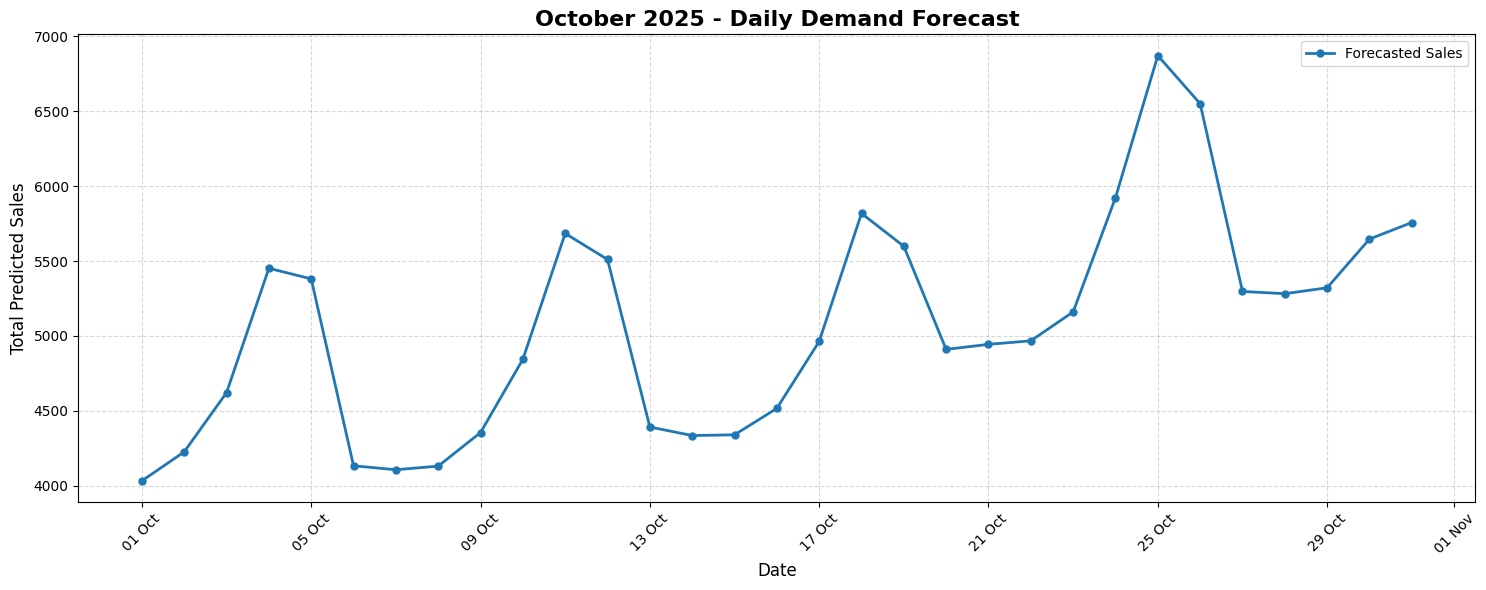

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

daily_forecast = forecast_df.groupby("date")[
    "predicted_sales"
].sum()

plt.figure(figsize=(15, 6))

plt.plot(
    daily_forecast.index,
    daily_forecast.values,
    marker="o",
    linewidth=2,
    markersize=5,
    label="Forecasted Sales"
)

plt.title(
    "October 2025 - Daily Demand Forecast",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Date", fontsize=12)
plt.ylabel("Total Predicted Sales", fontsize=12)

plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b")
)

plt.xticks(rotation=45)

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import mean_absolute_error

def evaluate_model(actual, predicted):

    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    wape = (
        np.sum(np.abs(actual - predicted))
        / np.sum(np.abs(actual))
    ) * 100

    mae = mean_absolute_error(actual, predicted)

    bias = (
        np.sum(predicted - actual)
        / np.sum(np.abs(actual))
    ) * 100

    return wape, mae, bias


wape, mae, bias = evaluate_model(
    y_valid,
    predictions
)

print("LightGBM Evaluation Results")
print("---------------------------")
print(f"WAPE: {wape:.2f}%")
print(f"MAE: {mae:.2f}")
print(f"Forecast Bias: {bias:.2f}%")

LightGBM Evaluation Results
---------------------------
WAPE: 45.53%
MAE: 5.77
Forecast Bias: -0.05%


In [ ]:
validation_starts = [
    max_date - pd.Timedelta(days=83),
    max_date - pd.Timedelta(days=55),
    max_date - pd.Timedelta(days=27)
]

rolling_results = []

for i, start_date in enumerate(validation_starts):
    end_date = start_date + pd.Timedelta(days=27)

    # Corrected: Using hist_df (historical feature store) instead of df
    train = hist_df[hist_df["date"] < start_date].copy()
    valid = hist_df[
        (hist_df["date"] >= start_date) &
        (hist_df["date"] <= end_date)
    ].copy()

    if train.empty or valid.empty:
        print(f"Skipping Fold {i+1}: insufficient data")
        continue

    X_tr = train[feature_cols].copy()
    y_tr = train["units_sold"]

    X_val = valid[feature_cols].copy()
    y_val = valid["units_sold"]

    # Include 'festival' in the categorical conversion
    for col in categorical_cols + ["festival"]:
        if col in X_tr.columns:
            X_tr[col] = X_tr[col].astype("category")
            X_val[col] = X_val[col].astype("category")
            X_val[col] = X_val[col].cat.set_categories(
                X_tr[col].cat.categories
            )

    fold_model = lgb.LGBMRegressor(
        n_estimators=500,
        learning_rate=0.05,
        num_leaves=31,
        random_state=42,
        verbosity=-1
    )

    fold_model.fit(X_tr, y_tr)

    pred = np.maximum(fold_model.predict(X_val), 0)

    fold_wape, fold_mae, fold_bias = evaluate_model(
        y_val, pred
    )

    rolling_results.append({
        "Fold": i + 1,
        "Start_Date": start_date,
        "End_Date": end_date,
        "WAPE": fold_wape,
        "MAE": fold_mae,
        "Bias": fold_bias
    })

rolling_df = pd.DataFrame(rolling_results)
print(rolling_df)

   Fold Start_Date   End_Date       WAPE       MAE      Bias
0     1 2025-07-09 2025-08-05  43.886283  5.410614  0.186223
1     2 2025-08-06 2025-09-02  48.383606  6.511638 -7.397621
2     3 2025-09-03 2025-09-30  45.527168  5.766764 -0.047344


In [ ]:
print("Average Rolling CV Performance")

print("WAPE:", rolling_df["WAPE"].mean())
print("MAE:", rolling_df["MAE"].mean())
print("Bias:", rolling_df["Bias"].mean())

Average Rolling CV Performance
WAPE: 45.93235244622232
MAE: 5.896338915720889
Bias: -2.4195805324937805


In [ ]:
comparison_df = pd.DataFrame({
    "Model": [
        "Seasonal Naive",
        "Moving Average",
        "ETS",
        "LightGBM"
    ],
    "WAPE": [
        60.99,
        53.28,
        46.23,
        rolling_df["WAPE"].mean()
    ]
})

print(comparison_df)

            Model       WAPE
0  Seasonal Naive  60.990000
1  Moving Average  53.280000
2             ETS  46.230000
3        LightGBM  45.932352


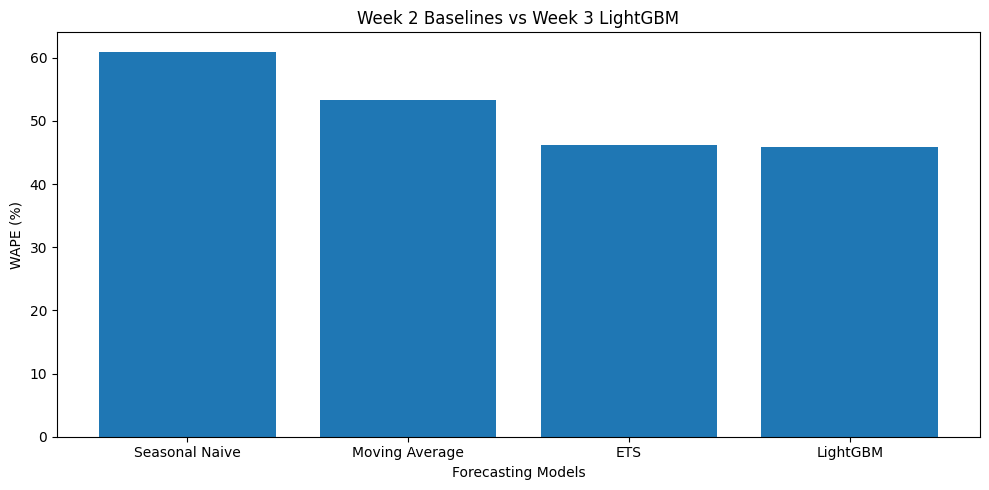

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["WAPE"]
)

plt.title("Week 2 Baselines vs Week 3 LightGBM")
plt.xlabel("Forecasting Models")
plt.ylabel("WAPE (%)")

plt.tight_layout()
plt.show()

In [ ]:
importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(15))

            Feature  Importance
12            lag_1        2792
13            lag_7        2466
15           lag_28        1454
14           lag_14        1200
1            sku_id        1084
16   rolling_mean_7         904
18  rolling_mean_28         847
9      week_of_year         747
7               day         728
8       day_of_week         598
17  rolling_mean_14         596
2     selling_price         477
0          store_id         344
4      discount_pct         301
5              year         158


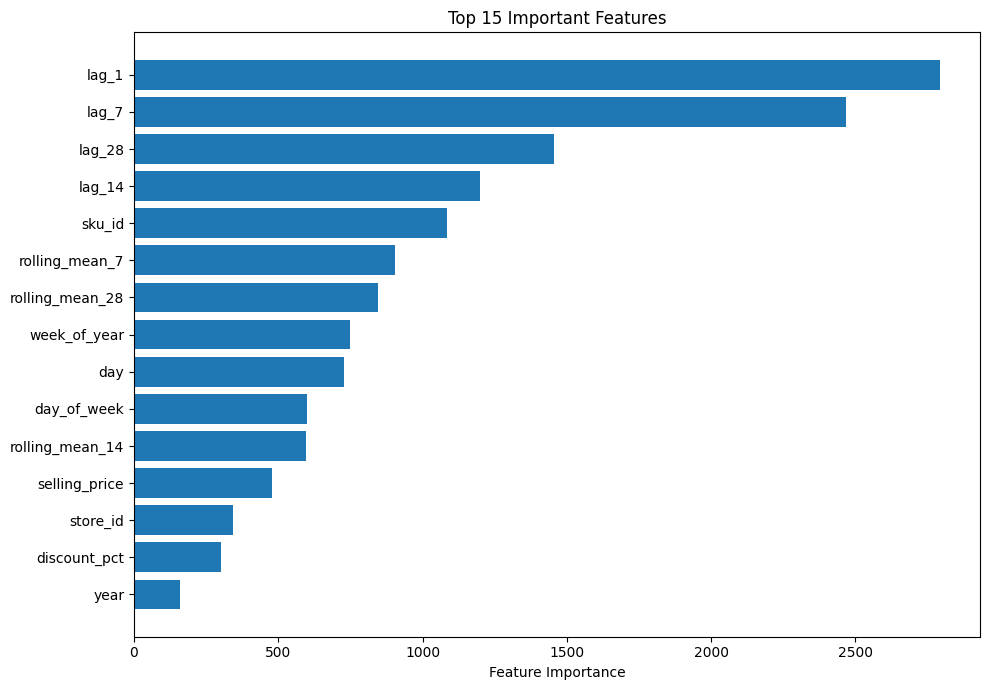

In [ ]:
plt.figure(figsize=(10, 7))

top_features = importance_df.head(15)

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.title("Top 15 Important Features")
plt.xlabel("Feature Importance")

plt.tight_layout()
plt.show()

In [ ]:
store_results = results_df.groupby("store_id").apply(
    lambda g: pd.Series({
        "Actual_Sales": g["units_sold"].sum(),
        "Predicted_Sales": g["predicted_sales"].sum(),
        "WAPE": (
            np.abs(g["units_sold"] - g["predicted_sales"]).sum()
            / np.abs(g["units_sold"]).sum() * 100
        ) if g["units_sold"].abs().sum() != 0 else np.nan
    }),
    include_groups=False
).reset_index()

print(store_results)

  store_id  Actual_Sales  Predicted_Sales       WAPE
0      S01       38649.0     39167.698654  43.484709
1      S02       16993.0     16628.322542  43.666913
2      S03       33819.0     33736.676464  44.113939
3      S04       17629.0     16743.479455  46.195563
4      S05       17722.0     17748.209395  44.656811
5      S06        7768.0      7919.549219  51.880250
6      S07       16676.0     16813.217475  46.916904
7      S08        6648.0      6712.351001  54.699929
8      S09        7543.0      7793.935109  50.484018
9      S10       13800.0     13899.604407  44.862586


In [ ]:
store_results.to_csv(
    "week3_store_performance.csv",
    index=False
)

In [ ]:
final_model = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    verbosity=-1
)

# Extract features and target from hist_df instead of df
X_all = hist_df[feature_cols].copy()
y_all = hist_df["units_sold"].copy()

# Include 'festival' in categorical casting along with other categoricals
for col in categorical_cols + ["festival"]:
    if col in X_all.columns:
        X_all[col] = X_all[col].astype("category")

final_model.fit(X_all, y_all)

print("Final LightGBM model trained on all historical data!")

Final LightGBM model trained on all historical data!


In [ ]:
future_df = pd.read_csv("/content/october_2025_forecast_features.csv")
future_df.columns = future_df.columns.str.strip().str.lower()
future_df["date"] = pd.to_datetime(future_df["date"])

# Create missing date features in future_df
future_df["week_of_year"] = future_df["date"].dt.isocalendar().week.astype(int)
future_df["quarter"] = future_df["date"].dt.quarter

# Populate missing features with default values instead of raising an error
for col in feature_cols:
    if col not in future_df.columns:
        if col == "festival":
            future_df[col] = "none"
        else:
            future_df[col] = 0

print("All required future features are initialized successfully!")

X_future = future_df[feature_cols].copy()

# Align categorical columns (including festival)
for col in categorical_cols + ["festival"]:
    if col in X_future.columns:
        X_future[col] = X_future[col].astype("category")
        X_future[col] = X_future[col].cat.set_categories(
            X_all[col].cat.categories
        )

All required future features are initialized successfully!


In [ ]:
october_predictions = final_model.predict(X_future)

october_predictions = np.maximum(october_predictions, 0)

forecast_df = future_df[
    ["date", "store_id", "sku_id"]
].copy()

forecast_df["predicted_sales"] = october_predictions

forecast_df.to_csv(
    "October_2025_LightGBM_Forecast.csv",
    index=False
)

print("October 2025 forecast generated successfully!")
print(forecast_df.head())

October 2025 forecast generated successfully!
        date store_id sku_id  predicted_sales
0 2025-10-01      S01   P001        46.653154
1 2025-10-01      S01   P002        19.504821
2 2025-10-01      S01   P003        14.321842
3 2025-10-01      S01   P004        44.613705
4 2025-10-01      S01   P005        30.770874


In [ ]:
# Save validation results
rolling_df.to_csv(
    "week3_rolling_validation.csv",
    index=False
)

# Save model comparison
comparison_df.to_csv(
    "week3_model_comparison.csv",
    index=False
)

# Save feature importance
importance_df.to_csv(
    "week3_feature_importance.csv",
    index=False
)

# Save validation predictions
results_df.to_csv(
    "week3_validation_predictions.csv",
    index=False
)

# Save trained model
joblib.dump(
    final_model,
    "week3_lightgbm_model.pkl"
)

print("All Week 3 deliverables saved successfully!")

All Week 3 deliverables saved successfully!
